# 2.04 · MiBici model evaluation: rolling-origin backtest and the champion

**Phase 2 (model building)** following the [Cookiecutter Data Science](https://cookiecutter-data-science.drivendata.org/using-the-template/) convention: `PHASE.NOTEBOOK-initials-description`. It runs after `2.03`, which tuned the two finalists `lgbm_tweedie` and `hgb_poisson`.

- **Input:** the MLflow runs of `python -m team2_mlops2026.modeling.train backtest` and `... ablation`:
  - one parent run `backtest-<model>` per baseline and finalist, with one nested run per fold (`fold-2025-10` ... `fold-2026-09`), and the fold table, the error by hour, the decision metric, the out-of-sample forecasts, the permutation importance and the figures as artifacts under `backtest/`
  - one run `ablation-<model>-<target>-pca` / `-no-pca` per finalist and target, tagged `experiment=pca_ablation`
- **Output:** the champion of each target, with the numbers that justify it, for the Model Registry (`2.05`, #27).

**Why.** `2.02` and `2.03` scored the models on one split: trained until 2025-09 and tested on the next 12 months at once. The [ML Canvas](../references/ml-canvas.md) (§4, Impact simulation) asks for a rolling-origin backtest instead: train up to month *m*, forecast month *m + 1*, move one month on, as the monthly retraining would. Each of the 12 folds refits every model from scratch, the finalists with the params of their `tune-<model>-<target>` run. The success criterion is applied to the mean over the folds: **a peak-hour WAPE at least 10% lower than the best baseline, with no demand group worse.**

1. The backtest in MLflow and its lineage.
2. The mean and the spread over the 12 folds.
3. Success criterion and champion.
4. Error per test month: drift.
5. Error by hour of the day.
6. Decision metric: high-imbalance station-days.
7. Forecasts against actual values.
8. Permutation importance.
9. PCA ablation: does PCA help the model?

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

os.environ["MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR"] = "false"  # keep the outputs readable

import mlflow
import numpy as np
import pandas as pd

from team2_mlops2026 import plots
from team2_mlops2026.config import MLFLOW_EXPERIMENT_NAME, MLFLOW_TRACKING_URI
from team2_mlops2026.features import RUN_NAME as FEATURES_RUN
from team2_mlops2026.features import STATION, TARGETS, TIME
from team2_mlops2026.modeling.backtest import (
    ABLATION_PREFIX,
    ARTIFACT_DIR,
    BACKTEST_MODELS,
    BY_HOUR_FILE,
    FOLD,
    FORECAST,
    FORECASTS_FILE,
    IMBALANCE_FILE,
    NEW_SINCE,
    NEW_STATIONS,
    load_backtests,
    new_stations,
    rank_backtests,
    sample_stations,
)
from team2_mlops2026.modeling.evaluate import MIN_IMPROVEMENT, N_FOLDS, success_criterion
from team2_mlops2026.modeling.models import BASELINES
from team2_mlops2026.modeling.tuning import FINALISTS
from team2_mlops2026.modeling.tuning import RUN_PREFIX as TUNE_PREFIX
from team2_mlops2026.station_profiles import RUN_NAME as PROFILES_RUN
from team2_mlops2026.tracking import input_digests, latest_run

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plots.use_style()
mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)

/Users/xavier/code/tecmty/mlops/fase2Proyecto/MLOps_Team2/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-07 16:19:59.413 | INFO     | team2_mlops2026.config:<module>:12 - PROJ_ROOT path is: /Users/xavier/code/tecmty/mlops/fase2Proyecto/MLOps_Team2


## Parameters

`METRICS` are the ones the canvas fixes (WAPE, MAE and Poisson deviance), at the segments the success criterion reads: overall, at weekday peak hours, and the daily WAPE of the quietest stations (group 1) and of the stations opened since May 2026.

In [3]:
METRICS = [
    "overall_wape",
    "peak_wape",
    "overall_mae",
    "peak_mae",
    "overall_poisson_deviance",
    "group_1_daily_wape",
    f"{NEW_STATIONS}_daily_wape",
]
GROUPS = [f"group_{i}" for i in range(1, 6)]
ABLATION_METRICS = [
    "overall_wape",
    "peak_wape",
    "overall_poisson_deviance",
    "group_1_daily_wape",
    "unseen_stations_daily_wape",
]


def artifact(run, name: str) -> str:
    """Local path of the backtest artifact ``name`` of ``run``."""
    return mlflow.artifacts.download_artifacts(
        run_id=run.info.run_id, artifact_path=f"{ARTIFACT_DIR}/{name}"
    )


def fold_reports(table: pd.DataFrame, target: str) -> dict[str, pd.DataFrame]:
    """The segment report of each fold, from a model's fold table."""
    rows = table[table["target"] == target]
    return {
        fold: r.drop(columns=[FOLD, "target"]).set_index("segment")
        for fold, r in rows.groupby(FOLD)
    }

## 1. The backtest in MLflow

The notebook reads the latest finished `backtest-<model>` run of each model, and its fold table (`backtest/folds.csv`: one row per fold, target and segment). Three checks:
- every parent run has its 12 nested fold runs, finished;
- its input digests are those of the latest `build-station-hour-features` and `fit-station-profiles` runs, so all models read the same data;
- each finalist took its params from the latest `tune-<model>-<target>` run, the one `2.03` analysed.

In [4]:
backtests = load_backtests(BACKTEST_MODELS)
runs = {name: run for name, (run, _) in backtests.items()}
fold_tables = {name: table for name, (_, table) in backtests.items()}

upstream = {}
for run_name in (FEATURES_RUN, PROFILES_RUN):
    upstream |= input_digests(latest_run(run_name).info.run_id)

overview = {}
for name, run in runs.items():
    nested = mlflow.search_runs(
        experiment_names=[MLFLOW_EXPERIMENT_NAME],
        filter_string=f"tags.mlflow.parentRunId = '{run.info.run_id}'",
    )
    assert len(nested) == int(run.data.params["n_folds"]) == N_FOLDS
    assert (nested["status"] == "FINISHED").all()
    logged = input_digests(run.info.run_id)
    assert logged == {k: upstream[k] for k in logged}
    for target in TARGETS:
        source = run.data.tags[f"params_from_{target}"]
        if name in FINALISTS:
            assert source == latest_run(f"{TUNE_PREFIX}-{name}-{target}").info.run_id
    overview[name] = {
        "family": run.data.tags["model_family"],
        "parent run": run.info.run_id,
        "fold runs": len(nested),
        "test months": f"{run.data.params['first_test_month']} to {run.data.params['last_test_month']}",
        "params": "tuned" if name in FINALISTS else "rule",
        "fit minutes": round(sum(run.data.metrics[f"{t}_fit_seconds"] for t in TARGETS) / 60, 1),
    }
print(f"Experiment '{MLFLOW_EXPERIMENT_NAME}' ({MLFLOW_TRACKING_URI})")
pd.DataFrame(overview).T

Experiment 'mibici' (http://127.0.0.1:5001)


,family,parent run,fold runs,test months,params,fit minutes
seasonal_naive,baseline,78f86f082312425db4cdd4c2e2904407,12,2025-10 to 2026-09,rule,0.2
historical_average,baseline,8e7a90b6420740b3b34d651e043ca70f,12,2025-10 to 2026-09,rule,0.2
lgbm_tweedie,boosting,d4deed918b414e24b26fd1ebf40883cb,12,2025-10 to 2026-09,tuned,73.3
hgb_poisson,boosting,cf2fae4aae2c4c6f8f60ac1292caf914,12,2025-10 to 2026-09,tuned,95.7


**Result → action.** The four parent runs have their 12 fold runs, all finished, and read the feature and profile tables of the latest feature runs, so every model saw the same data. Both finalists took their params from the latest `tune-<model>-<target>` runs, the ones `2.03` analysed. Refitting the 12 folds of both targets took 73 minutes for `lgbm_tweedie` and 96 for `hgb_poisson`; the baselines take seconds. → The comparison below is fair, and `lgbm_tweedie` is the cheaper finalist to retrain every month.

## 2. The mean and the spread over the 12 folds

Each parent run logs the mean of every fold metric as `<target>_<segment>_<metric>` and its standard deviation with a `_std` suffix. These are the columns to select in the MLflow UI: filter the runs with `attributes.run_name LIKE 'backtest-%'`, open **Compare**, and the bar charts show each model side by side. In the **Chart** view, the step metrics `fold_<target>_peak_wape` draw one line per model across the 12 folds.

In [5]:
mean = pd.DataFrame(
    {
        (name, target): {m: run.data.metrics.get(f"{target}_{m}", np.nan) for m in METRICS}
        for name, run in runs.items()
        for target in TARGETS
    }
).T.rename_axis(["model", "target"])
std = pd.DataFrame(
    {
        (name, target): {m: run.data.metrics.get(f"{target}_{m}_std", np.nan) for m in METRICS}
        for name, run in runs.items()
        for target in TARGETS
    }
).T.rename_axis(["model", "target"])
order = pd.MultiIndex.from_product([TARGETS, BACKTEST_MODELS], names=["target", "model"])
(mean.round(3).astype(str) + " ± " + std.round(3).astype(str)).swaplevel().reindex(order)

overall_wape      peak_wape    overall_mae       peak_mae overall_poisson_deviance group_1_daily_wape new_stations_daily_wape
target     model                                                                                                                                             
departures seasonal_naive      0.753 ± 0.053  0.653 ± 0.057  0.912 ± 0.052  1.562 ± 0.089             6.124 ± 0.63      0.444 ± 0.068           0.868 ± 0.588
           historical_average  0.679 ± 0.072  0.614 ± 0.081   0.82 ± 0.043  1.462 ± 0.093            1.126 ± 0.151      0.474 ± 0.207           1.282 ± 0.731
           lgbm_tweedie         0.611 ± 0.04   0.52 ± 0.042   0.74 ± 0.039  1.243 ± 0.068            0.921 ± 0.072      0.334 ± 0.038           0.454 ± 0.194
           hgb_poisson         0.613 ± 0.041  0.521 ± 0.043  0.741 ± 0.039  1.245 ± 0.068            0.921 ± 0.069      0.335 ± 0.039           0.478 ± 0.217
arrivals   seasonal_naive       0.724 ± 0.05  0.603 ± 0.052  0.876 ± 0.048  1.442 ± 0.078            5.802 ± 0.611      0.503 ± 0.069           1.126 ± 1.023
           historical_average  0.657 ± 0.072  0.569 ± 0.079  0.792 ± 0.041  1.354 ± 0.084            1.085 ± 0.161      0.539 ± 0.177            1.59 ± 1.096
           lgbm_tweedie        0.591 ± 0.039  0.483 ± 0.039  0.715 ± 0.037  1.155 ± 0.061            0.884 ± 0.071      0.381 ± 0.033           0.523 ± 0.293
           hgb_poisson         0.594 ± 0.039  0.488 ± 0.038  0.719 ± 0.037  1.166 ± 0.064            0.887 ± 0.067      0.382 ± 0.033           0.555 ± 0.324

Success bar (peak WAPE at most): {'departures': 0.553, 'arrivals': 0.512}


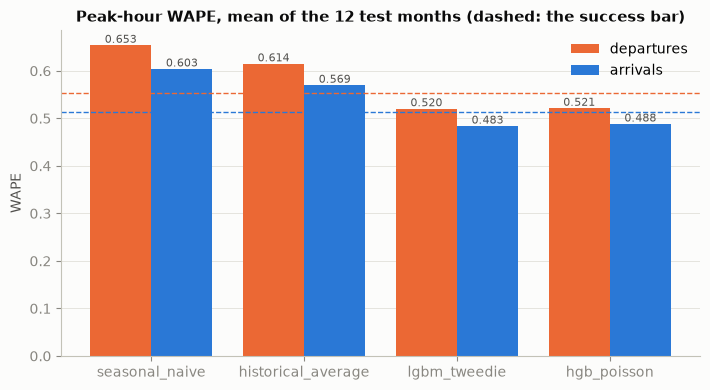

In [6]:
peak = mean["peak_wape"].unstack("target").loc[list(BACKTEST_MODELS), list(TARGETS)]
bar = {t: (1 - MIN_IMPROVEMENT) * peak.loc[list(BASELINES), t].min() for t in TARGETS}
print("Success bar (peak WAPE at most):", {t: round(float(v), 3) for t, v in bar.items()})
plots.plot_grouped_bars(
    peak, "Peak-hour WAPE, mean of the 12 test months (dashed: the success bar)", "WAPE", bar
);

**Result → action.** Both finalists beat both baselines in every metric, on the mean of the 12 months:
- Peak-hour WAPE: 0.520 (`lgbm_tweedie`) and 0.521 (`hgb_poisson`) for departures, against 0.614 for `historical_average` and 0.653 for `seasonal_naive`. For arrivals: 0.483 and 0.488 against 0.569 and 0.603. Both are under the success bar (0.553 and 0.512).
- Their spread over the months is half that of `historical_average` (std 0.04 against 0.08): they are also more stable.
- The quietest stations (group 1) gain the most: daily WAPE 0.334 against 0.444 for the best baseline, on departures.
- `seasonal_naive` has a Poisson deviance of 6, against 0.9 for the finalists, because it forecasts zeros where trips happen.

The two finalists are within 0.001-0.005 of each other, far less than the spread over the months. → Accuracy alone does not separate them; the criterion fold by fold and the cost decide (next section).

## 3. Success criterion and champion

`rank_backtests` applies `success_criterion` to the mean report of each finalist over the 12 folds, against the best baseline at peak hours, and ranks the finalists: the ones that pass first, then by peak-hour WAPE. The demand groups are compared on their daily WAPE (canvas §4). The first row of each target is the champion if it passed; the second is the challenger.

In [7]:
rankings = rank_backtests(fold_tables)
pd.concat(rankings, names=["target"]).round(3)

peak_wape            baseline  peak_wape_improvement worse_groups  passed
target     model                                                                                  
departures lgbm_tweedie      0.520  historical_average                  0.154                 True
           hgb_poisson       0.521  historical_average                  0.152                 True
arrivals   lgbm_tweedie      0.483  historical_average                  0.151                 True
           hgb_poisson       0.488  historical_average                  0.144                 True

The criterion on the mean could hide a bad month. The same check, fold by fold:

In [8]:
monthly = {}
for target in TARGETS:
    baseline_folds = {b: fold_reports(fold_tables[b], target) for b in BASELINES}
    for name in FINALISTS:
        for fold, report in fold_reports(fold_tables[name], target).items():
            check = success_criterion(report, {b: baseline_folds[b][fold] for b in BASELINES})
            monthly[name, target, fold] = {
                "baseline": check.baseline,
                "improvement": check.peak_wape_improvement,
                "worse groups": ", ".join(check.worse_groups),
                "passed": check.passed,
            }
monthly = pd.DataFrame(monthly).T.rename_axis(["model", "target", "fold"])
monthly["improvement"] = monthly["improvement"].astype(float)
monthly.groupby(level=["model", "target"]).agg(
    folds_passed=("passed", "sum"),
    min_improvement=("improvement", "min"),
    mean_improvement=("improvement", "mean"),
    max_improvement=("improvement", "max"),
).round(3)

folds_passed  min_improvement  mean_improvement  max_improvement
model        target                                                                     
hgb_poisson  arrivals              7            0.064             0.133            0.211
             departures           11            0.080             0.145            0.210
lgbm_tweedie arrivals             10            0.085             0.141            0.213
             departures           11            0.080             0.146            0.213

In [9]:
failed = monthly[~monthly["passed"].astype(bool)]
failed.round(3) if len(failed) else print("Every finalist passes the criterion in every fold")

baseline  improvement worse groups passed
model        target     fold                                                        
lgbm_tweedie departures 2026-09  historical_average        0.080               False
hgb_poisson  departures 2026-09  historical_average        0.080               False
lgbm_tweedie arrivals   2025-10  historical_average        0.096               False
                        2026-09  historical_average        0.085               False
hgb_poisson  arrivals   2025-10  historical_average        0.091               False
                        2025-11  historical_average        0.064               False
                        2026-02  historical_average        0.097               False
                        2026-03  historical_average        0.098               False
                        2026-09  historical_average        0.083               False

In [10]:
champions = {}
for target, table in rankings.items():
    champion = table.index[0]
    row = table.loc[champion]
    assert row["passed"], f"No finalist passes the success criterion for {target}"
    champions[target] = champion
    challenger = table.index[1] if len(table) > 1 else row["baseline"]
    print(
        f"{target}: champion {champion}, peak WAPE {row['peak_wape']:.3f}, "
        f"{row['peak_wape_improvement']:.1%} below {row['baseline']} "
        f"({peak.loc[row['baseline'], target]:.3f}); groups worse: {row['worse_groups'] or 'none'}. "
        f"Challenger: {challenger}"
    )

departures: champion lgbm_tweedie, peak WAPE 0.520, 15.4% below historical_average (0.614); groups worse: none. Challenger: hgb_poisson
arrivals: champion lgbm_tweedie, peak WAPE 0.483, 15.1% below historical_average (0.569); groups worse: none. Challenger: hgb_poisson


**Result → action.** Both finalists pass the success criterion on the mean of the 12 folds, for both targets, with no demand group worse than the baseline:
- Departures: `lgbm_tweedie` has a peak-hour WAPE 15.4% below `historical_average` (0.520 against 0.614).
- Arrivals: 15.1% below it (0.483 against 0.569).

`lgbm_tweedie` ranks first in both targets, so it is the **champion**, with `hgb_poisson` as the challenger.

Fold by fold, `lgbm_tweedie` passes 11 of 12 months for departures and 10 of 12 for arrivals. In the months it misses, it still beats the baseline by 8.0-9.6%, just below the 10% bar: September 2026 (both targets) and October 2025 (arrivals). `hgb_poisson` passes only 7 of 12 months for arrivals (6.4% at worst).

→ Register `lgbm_tweedie` as the champion and `hgb_poisson` as the challenger of both targets (`2.05`, `modeling.registry`). The criterion is read on the mean of the months, as the canvas sets it. A single month below 10% is a signal to watch in the monthly retraining, not a reason to fall back to the baseline.

## 4. Error per test month: drift

The canvas expects two changes in the test year: the record demand of September 2026, and about 100 stations opened between May and August 2026 (the `new_stations` segment, scored per station-day). Each line is a model; the baselines are dashed.

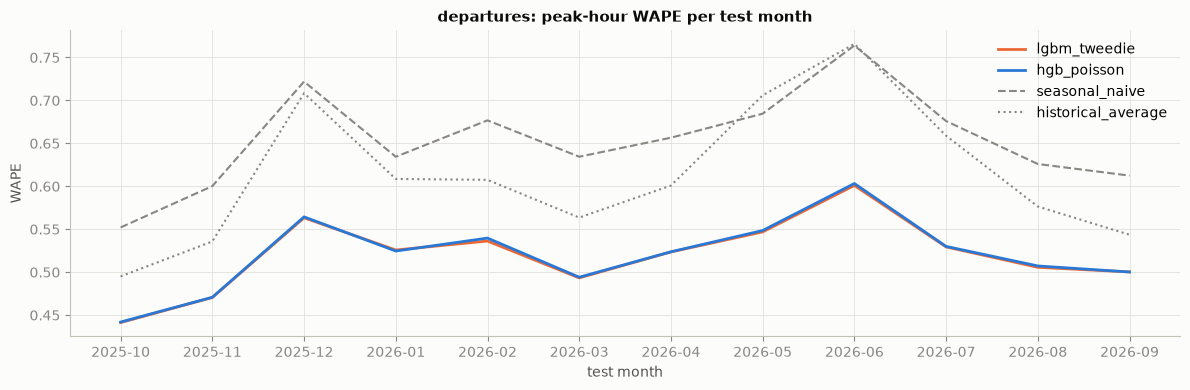

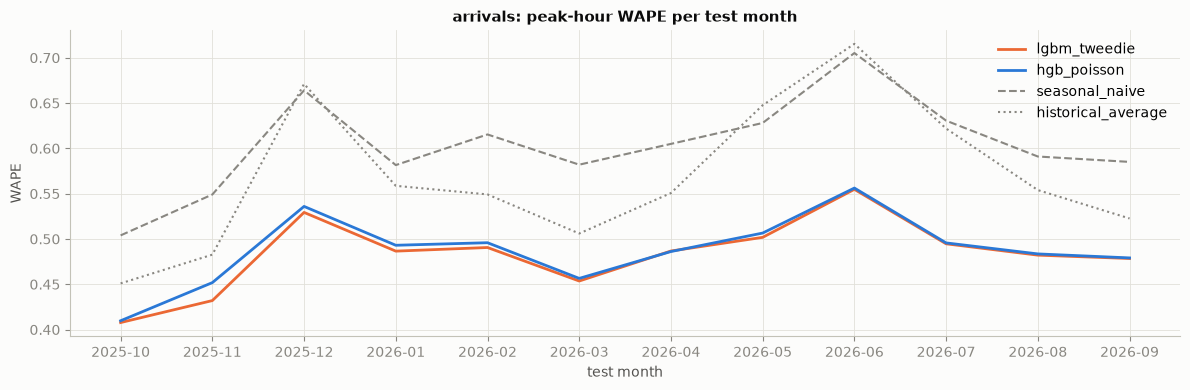

In [11]:
for target in TARGETS:
    by_month = pd.DataFrame(
        {
            name: table[(table["target"] == target) & (table["segment"] == "peak")].set_index(
                FOLD
            )["wape"]
            for name, table in fold_tables.items()
        }
    )
    plots.plot_lines(
        by_month,
        f"{target}: peak-hour WAPE per test month",
        "WAPE",
        "test month",
        muted=list(BASELINES),
    )

In [12]:
forecasts = {name: pd.read_parquet(artifact(run, FORECASTS_FILE)) for name, run in runs.items()}
first = next(iter(forecasts.values()))
new = new_stations(first, NEW_SINCE)  # first forecast hour in or after May 2026
for frame in forecasts.values():  # every model forecast the same station-hours, in the same order
    assert frame[[STATION, TIME]].equals(first[[STATION, TIME]])

champion = champions["departures"]
drift = pd.DataFrame(
    {
        "departures (thousands)": first.groupby(FOLD)["departures"].sum() / 1e3,
        "stations": first.groupby(FOLD)[STATION].nunique(),
        "new stations": first[first[STATION].isin(new)].groupby(FOLD)[STATION].nunique(),
    }
)
for name in (champion, *BASELINES):
    rows = fold_tables[name]
    rows = rows[(rows["target"] == "departures") & (rows["segment"] == NEW_STATIONS)]
    drift[f"{name}: new stations daily WAPE"] = rows.set_index(FOLD)["daily_wape"]
drift.fillna({"new stations": 0}).astype({"new stations": int}).round(3)

,departures (thousands),stations,new stations,lgbm_tweedie: new stations daily WAPE,seasonal_naive: new stations daily WAPE,historical_average: new stations daily WAPE
fold,,,,,,
2025-10,409.507,383,0,NaN,NaN,NaN
2025-11,370.220,383,0,NaN,NaN,NaN
2025-12,326.421,384,0,NaN,NaN,NaN
2026-01,346.645,384,0,NaN,NaN,NaN
2026-02,319.059,384,0,NaN,NaN,NaN
2026-03,364.815,384,0,NaN,NaN,NaN
2026-04,341.716,384,0,NaN,NaN,NaN
2026-05,305.117,396,12,0.767,1.785,2.008
2026-06,337.569,443,59,0.508,1.090,2.024


**Result → action.**
- December 2025 and June 2026 are the hardest months for every model: peak-hour WAPE 0.56 and 0.60 for the champion on departures, against 0.44-0.55 in the other months. Both finalists stay ahead of both baselines in every month.
- In September 2026, the month of record demand (470 thousand departures, 25% more than August), the champion keeps a WAPE of 0.50. The baselines improve too, so its margin shrinks to 8%.
- The stations opened since May 2026 grow from 12 active in May to 98 in August and September, out of 481. Their daily WAPE with the champion falls from 0.77 in May to 0.30 in September as they collect history. The baselines start at 1.8-2.0, since they have no history to repeat for a new station, and only get close in September (0.33-0.42).
- June is also the month with the largest wave of openings (from 396 to 443 stations). It was also the month of the World Cup matches in Guadalajara, a possible cause to check in the report.

→ The model forecasts a new station from its first month, using its own short history and the station attributes, and the monthly retraining absorbs the openings. Drift should be watched on the monthly peak WAPE: a month above about 0.60 calls for a look before the model is promoted again.

## 5. Error by hour of the day

WAPE of the out-of-sample forecasts of the 12 folds, per hour of the day (`backtest/error_by_hour.csv`).

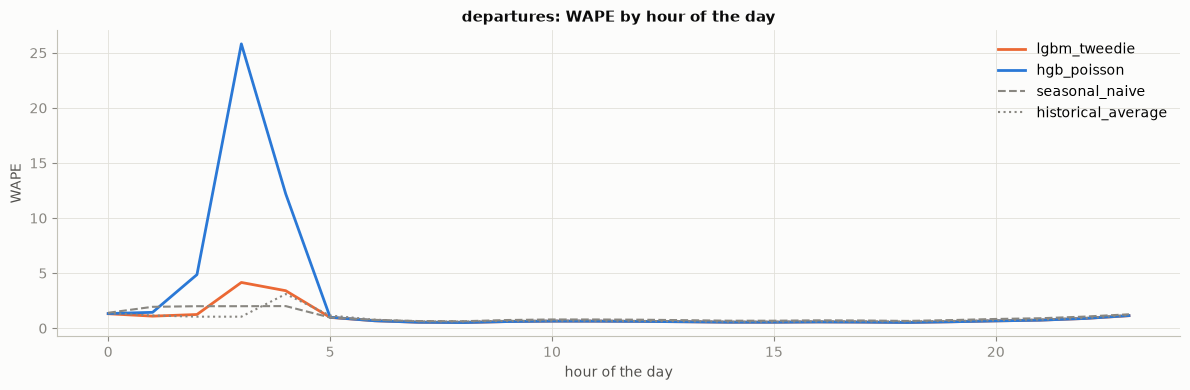

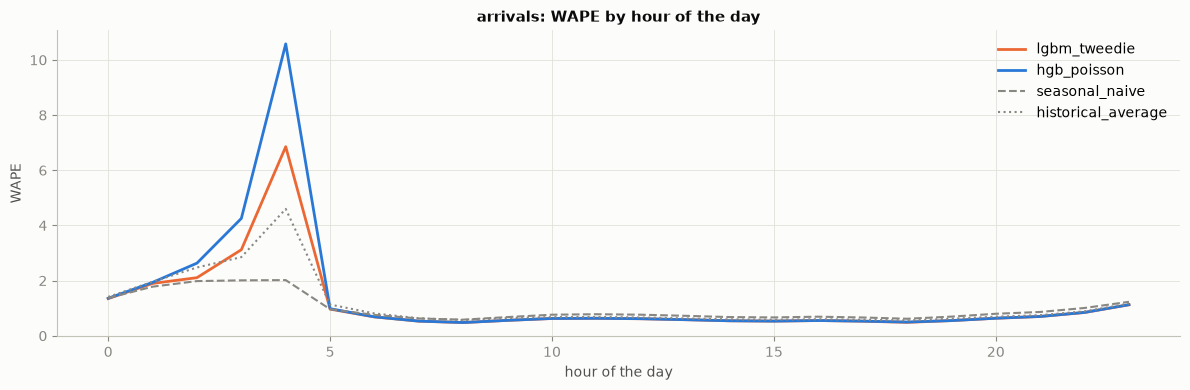

In [13]:
by_hour = {name: pd.read_csv(artifact(run, BY_HOUR_FILE)) for name, run in runs.items()}
for target in TARGETS:
    table = pd.DataFrame(
        {name: t[t["target"] == target].set_index("hour")["wape"] for name, t in by_hour.items()}
    )
    plots.plot_lines(
        table,
        f"{target}: WAPE by hour of the day",
        "WAPE",
        "hour of the day",
        muted=list(BASELINES),
    )

**Result → action.** From 06:00 to 21:00 the champion's WAPE stays between 0.48 and 0.73. It is lowest at the two daily peaks, which are the hours that matter for rebalancing:
- 08:00: 0.515 for departures and 0.478 for arrivals;
- 18:00: 0.524 and 0.486.

It beats both baselines at every one of these hours. From midnight to 04:00 the WAPE of every model explodes (above 1, and 25 for `hgb_poisson` at 03:00), because there are almost no trips: any small positive forecast is a large error relative to a near-zero total. `hgb_poisson` overshoots these hours far more than `lgbm_tweedie`, which is one more reason to prefer the latter.

→ The night hours do not affect the rebalancing decision. Forcing those forecasts to zero, or to the station's historical night mean, is a cheap later improvement; it is not needed for the success criterion.

## 6. Decision metric: high-imbalance station-days

Precision and recall in flagging the station-days whose absolute net flow exceeds half of the capacity (canvas §4), per fold. Each fold scores the departures and arrivals forecasts of the same model together.

In [14]:
imbalance = pd.concat(
    {
        name: pd.read_csv(artifact(run, IMBALANCE_FILE), index_col=FOLD)
        for name, run in runs.items()
    },
    names=["model"],
)
imbalance.groupby(level="model")[
    ["imbalance_days", "flagged_days", "imbalance_precision", "imbalance_recall"]
].mean().reindex(BACKTEST_MODELS).round(3)

,imbalance_days,flagged_days,imbalance_precision,imbalance_recall
model,,,,
seasonal_naive,1941.167,1954.083,0.477,0.480
historical_average,1941.167,1545.083,0.568,0.454
lgbm_tweedie,1941.167,1210.167,0.692,0.431
hgb_poisson,1941.167,1251.750,0.682,0.439


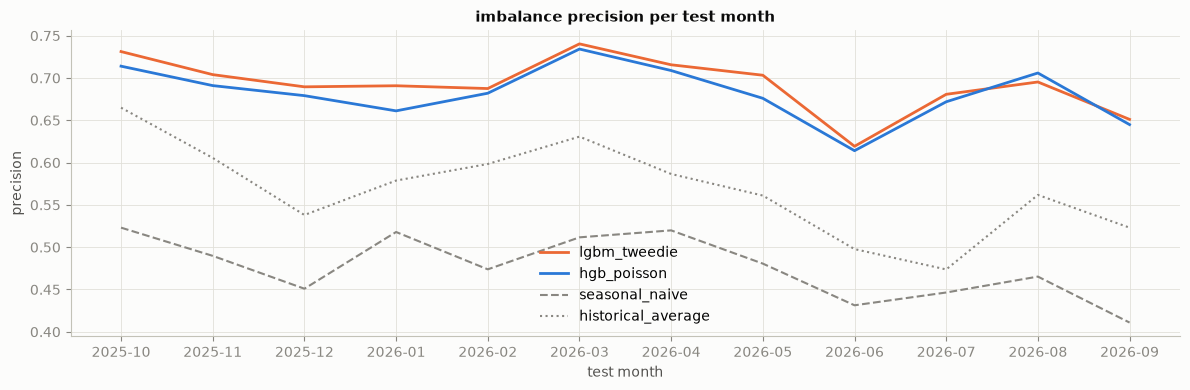

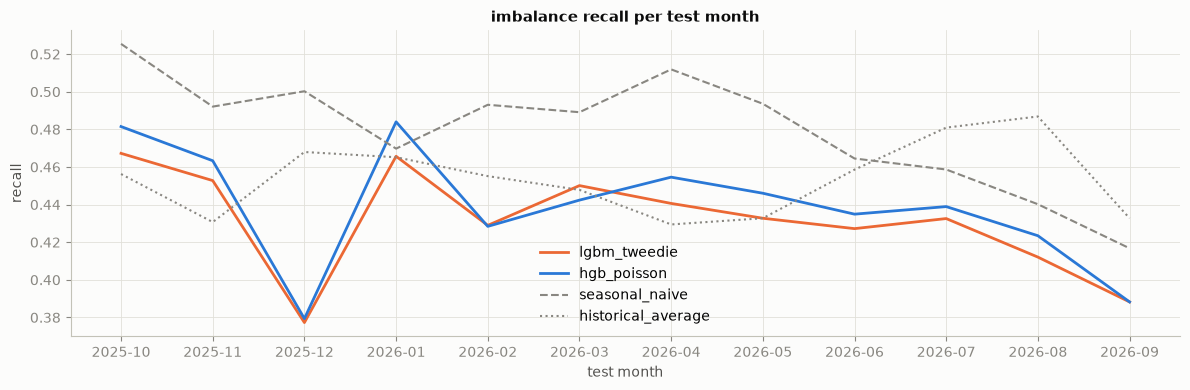

In [15]:
for metric in ("imbalance_precision", "imbalance_recall"):
    plots.plot_lines(
        imbalance[metric].unstack("model")[list(BACKTEST_MODELS)],
        f"{metric.replace('_', ' ')} per test month",
        metric.split("_")[1],
        "test month",
        muted=list(BASELINES),
    )

**Result → action.** Every month there are about 1,941 station-days whose real net flow exceeds half the station's capacity.
- `lgbm_tweedie` flags 1,210 of them, with a **precision of 0.69**: 7 of every 10 stations it flags really fill up or empty. `historical_average` reaches 0.57 and `seasonal_naive` 0.48, and the champion is more precise than both baselines in every month.
- Its **recall is 0.43**, against 0.45 for `historical_average` and 0.48 for `seasonal_naive`: it misses slightly more of the imbalanced days. A mean forecast smooths the extremes, so fewer station-days cross the threshold.

→ The operations team can trust the champion's alerts more than any baseline. To catch more of the imbalanced days, flag at a lower threshold on the forecast net flow, for example 40% of capacity instead of 50%. That trades some precision for recall without changing the model; it is a decision for the operation, worth showing in the report.

## 7. Forecasts against actual values

The first full week of the last test month, at three stations: the busiest, a median one and the busiest of the stations opened since May 2026. The champion against the best baseline, both refitted on the hours before September 2026.

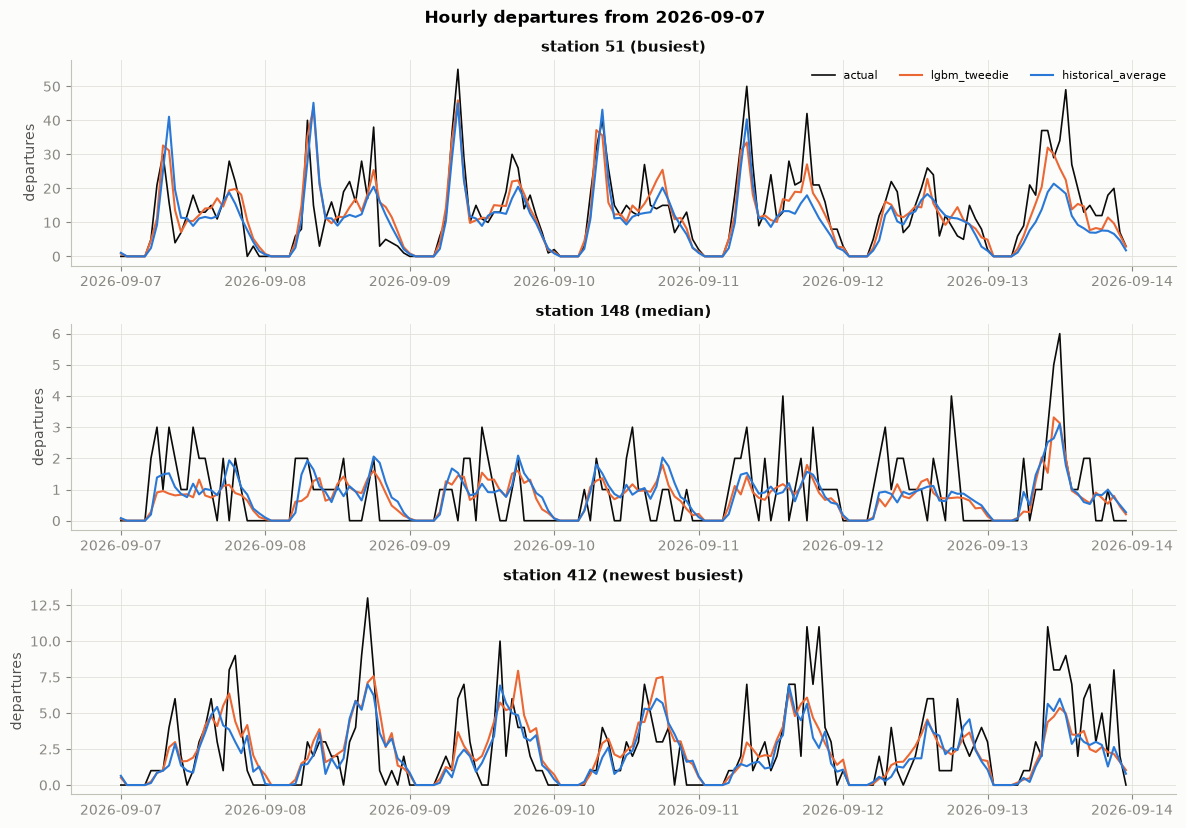

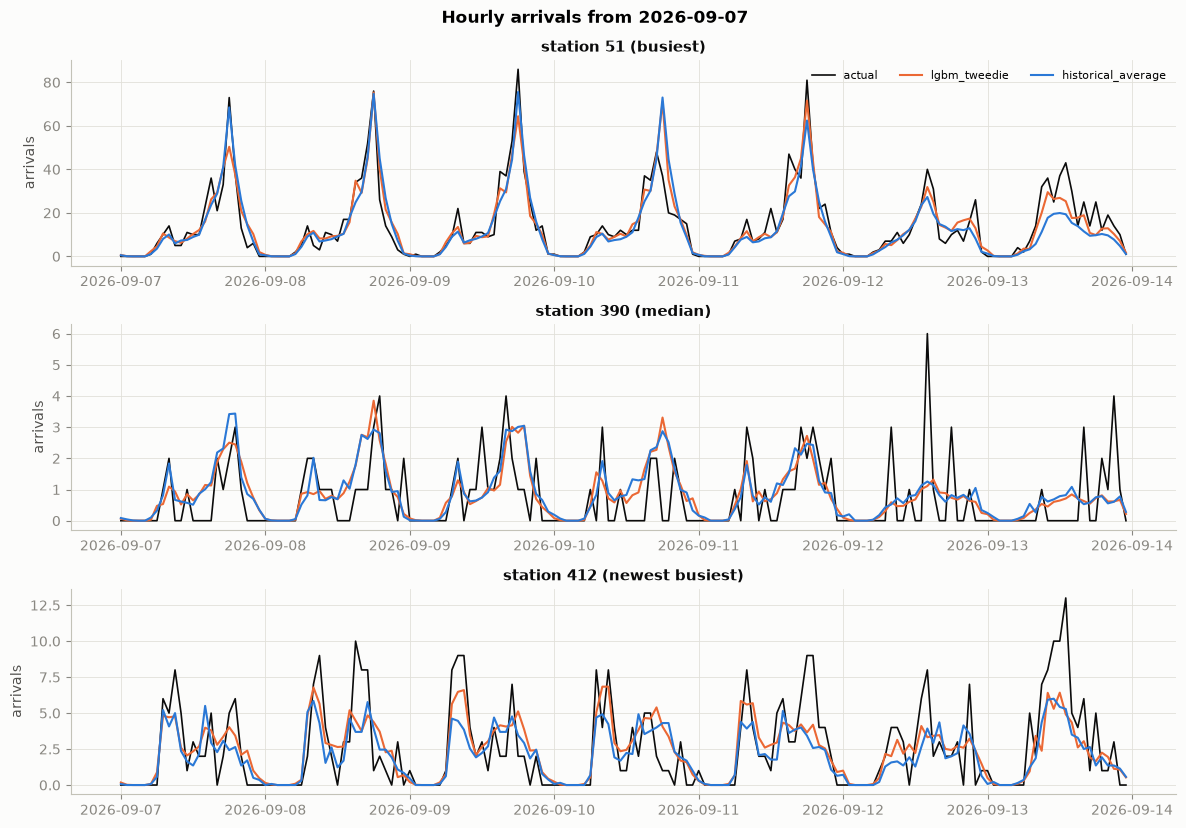

In [16]:
for target in TARGETS:
    champion = champions[target]
    baseline = rankings[target].loc[champion, "baseline"]
    last = first[FOLD].max()
    days = first.loc[first[FOLD] == last, TIME].dt.normalize()
    monday = days[days.dt.day_of_week == 0].min()
    week = (first[FOLD] == last) & first[TIME].between(
        monday, monday + pd.Timedelta(days=7), "left"
    )
    panels = {}
    for label, station in sample_stations(first, target, new).items():
        rows = week & (first[STATION] == station)
        panels[f"station {station} ({label})"] = pd.DataFrame(
            {
                "actual": first.loc[rows, target].to_numpy(),
                champion: forecasts[champion].loc[rows, FORECAST.format(target)].to_numpy(),
                baseline: forecasts[baseline].loc[rows, FORECAST.format(target)].to_numpy(),
            },
            index=first.loc[rows, TIME],
        )
    plots.plot_station_forecasts(panels, f"Hourly {target} from {monday:%Y-%m-%d}", target)

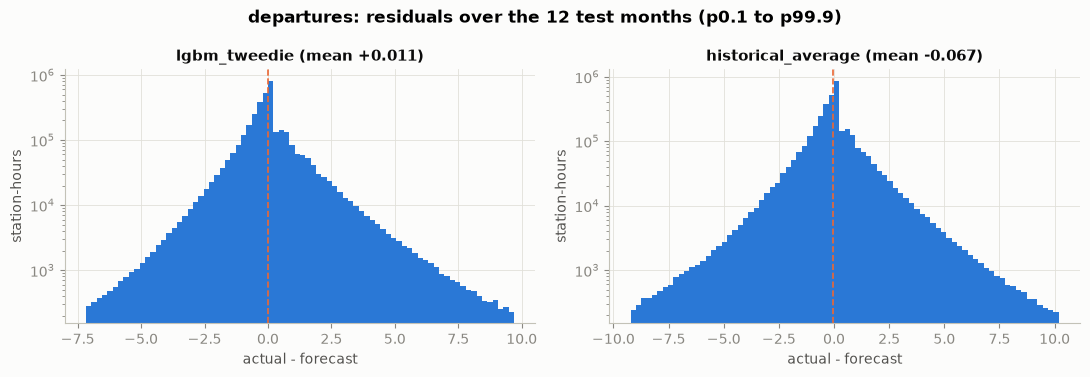

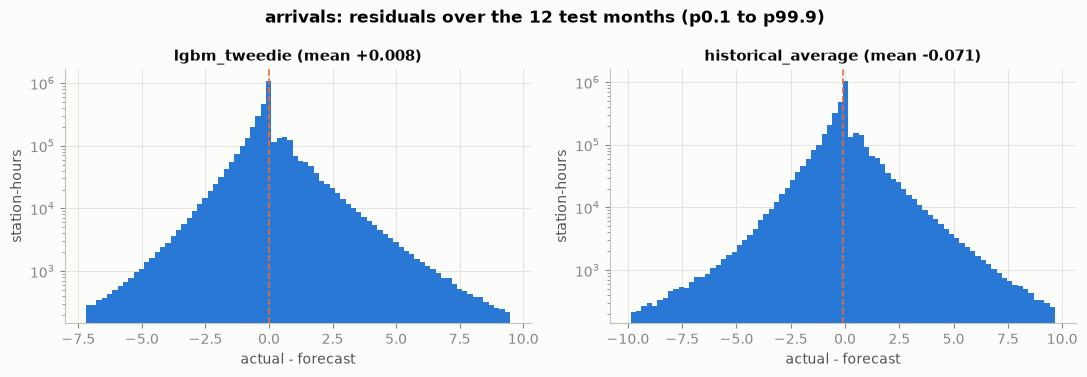

In [17]:
for target in TARGETS:
    champion = champions[target]
    baseline = rankings[target].loc[champion, "baseline"]
    plots.plot_residuals(
        pd.DataFrame(
            {
                name: forecasts[name][target] - forecasts[name][FORECAST.format(target)]
                for name in (champion, baseline)
            }
        ),
        f"{target}: residuals over the 12 test months",
    )

**Result → action.**
- **Station forecasts.** At the three stations, the champion follows the daily shape: the morning and evening peaks, the weekend pattern and the zeros at night. That includes station 412, opened after May 2026.
- **Peaks.** It smooths the hour-to-hour noise and falls short of the highest peaks: about 45 against 55 departures at station 51 on 9 September. That is expected from a forecast of the mean.
- **Residuals.** They have a mean of +0.011 for departures and +0.008 for arrivals, so the champion is practically unbiased. `historical_average` over-forecasts on average (-0.067 and -0.071), and its tails are wider.

→ The champion is suited to the daily rebalancing plan. If the operation needed an upper bound for the peaks, a later version could add a prediction interval from the Poisson or Tweedie distribution, or quantile models.

## 8. Permutation importance

How much the Poisson deviance of the champion rises when one input column is shuffled, on 50,000 hours of the last test month, refitted on all the hours before it. The columns are the raw inputs: `station_id` covers its target encoding, and `pc1`-`pc5` are the PCA profile scores.

,departures,arrivals
feature,,
hour_cos,1.2012,0.7768
departures_same_hour_4w,0.5259,0.0112
hour_sin,0.5161,0.3938
departures_mean_7d,0.2703,0.0844
station_id,0.2252,0.3357
weekday,0.0697,0.0794
arrivals_mean_7d,0.0671,0.2363
departures_lag_2d,0.0325,0.0019
arrivals_same_hour_4w,0.0117,0.4923


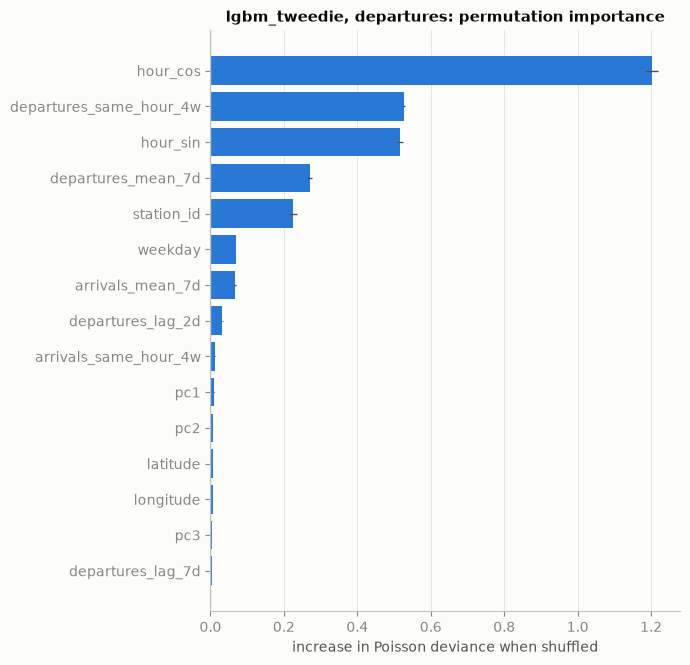

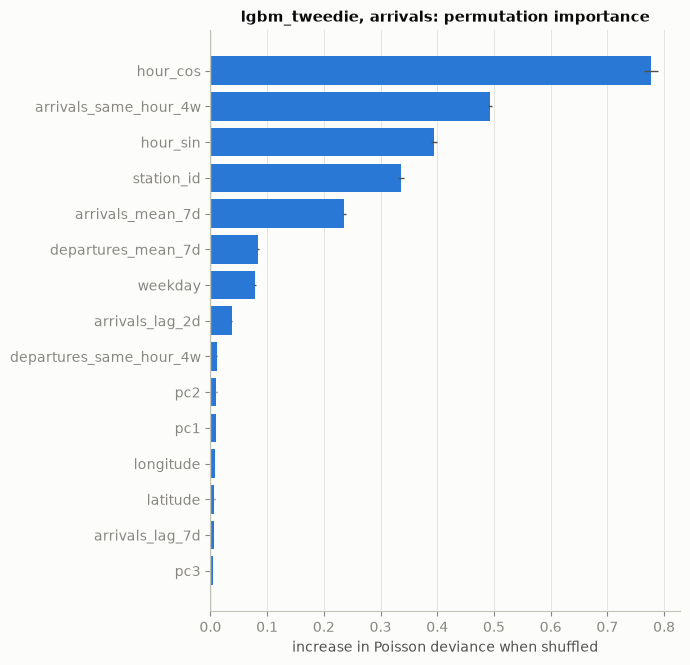

In [18]:
importance = {
    target: pd.read_csv(artifact(runs[champions[target]], f"importance_{target}.csv"), index_col=0)
    for target in TARGETS
}
for target, table in importance.items():
    plots.plot_importance(table, f"{champions[target]}, {target}: permutation importance")
pd.DataFrame({t: table["mean"] for t, table in importance.items()}).sort_values(
    TARGETS[0], ascending=False
).round(4)

**Result → action.** The time of day comes first: `hour_cos` and `hour_sin` cause the largest rise of the deviance. Then comes the station's own recent demand:
- departures of the same hour in the past 4 weeks (0.53 for the departures model);
- arrivals of the same hour in the past 4 weeks (0.49 for the arrivals model);
- the 7-day means;
- `station_id` through its target encoding (0.23 and 0.34).

Each model also reads the other target's 7-day mean: arrivals help forecast departures and the reverse. The PCA profile scores `pc1`-`pc5` add between 0.001 and 0.010: once the recent lags are known, the weekly profile tells the model little more. Three columns read 0:
- `month_sin` and `month_cos` are constant in a single test month;
- `hour_start` is not a model input: the preprocessor drops it after the calendar features are derived from it.

→ The demand lags and the hour carry the model. This matches the PCA ablation below.

## 9. PCA ablation: does PCA help the model?

The Phase 1 review asked whether the PCA station profiles (26 components for 90% of the variance in `1.05`; the models read the first five) really improve the model, or whether the original variables would do. Each finalist was scored on the test split of `2.02` (trained until 2025-09, tested on 2025-10 to 2026-09) with its tuned params, with and without the profile scores and their missing flag. The variant with the scores is the model the `tune-<model>-<target>` run already refitted on that split.

The original variables of the profile are 336 hour-of-week shares per station-week. Joined to 12.2 million station-hours they would need about 16 GB as float32, so the experiment compares the PCA summary with no profile at all.

In [19]:
ablation = mlflow.search_runs(
    experiment_names=[MLFLOW_EXPERIMENT_NAME],
    filter_string="tags.experiment = 'pca_ablation' and status = 'FINISHED'",
    order_by=["start_time DESC"],
)
ablation = ablation.drop_duplicates("tags.mlflow.runName")
assert set(ablation["tags.mlflow.runName"]) == {
    f"{ABLATION_PREFIX}-{name}-{target}-{variant}"
    for name in FINALISTS
    for target in TARGETS
    for variant in ("pca", "no-pca")
}
ablation["variant"] = np.where(
    ablation["tags.mlflow.runName"].str.endswith("-no-pca"), "without PCA", "with PCA"
)
pca = ablation.set_index(["params.model", "tags.target", "variant"])[
    [f"metrics.{m}" for m in ABLATION_METRICS]
].rename(columns=lambda c: c.removeprefix("metrics."))
pca = pca.unstack("variant").swaplevel(axis=1).sort_index(axis=1)
for m in ABLATION_METRICS:
    pca[("change", m)] = pca[("without PCA", m)] / pca[("with PCA", m)] - 1
pca = pca.rename_axis(["model", "target"])
pca[["with PCA", "without PCA", "change"]].style.format("{:.4f}").format(
    "{:+.2%}", subset=[("change", m) for m in ABLATION_METRICS]
)

**Result → action.** Removing the PCA profile scores makes both finalists slightly worse on both targets, in almost every metric:
- Peak-hour WAPE rises 0.2-0.6%. For `lgbm_tweedie` it goes from 0.5198 to 0.5227 for departures and from 0.4831 to 0.4849 for arrivals.
- The Poisson deviance rises 0.2-0.3%, and the daily WAPE of the quietest stations rises 0.2-0.5%.

The direction is consistent, but the size is small: 0.003 of peak WAPE, against a spread of 0.04 between months. On the stations not seen in training, which have no profile yet, the result is mixed. It goes either way, from -12% to +2%, because those stations are few and their metric is noisy.

→ Keep the PCA profiles. They cost 5 columns computed once a week and give a small, consistent gain. The answer to the Phase 1 review is that **PCA helps, but marginally**: the accuracy comes from the demand lags and the hour, as the permutation importance shows. The comparison is against no profile at all, since the 336 original hour-of-week shares would need about 16 GB.

## Findings and next steps

1. **Champion: `lgbm_tweedie` for both targets, with `hgb_poisson` as challenger.** Over 12 monthly folds (2025-10 to 2026-09), its peak-hour WAPE is 0.520 for departures and 0.483 for arrivals. That is 15.4% and 15.1% below the best baseline (`historical_average`), with no demand group worse, so it **passes the success criterion** (≥ 10%).
2. **Stable over time.** Its spread between months is half the baseline's. The margin falls below 10% in 2 of 12 months (September 2026, the record month, and October 2025 for arrivals) but never below 8%.
3. **The new stations are covered.** The about 100 stations opened since May 2026 reach a daily WAPE of 0.30 by September, from 0.77 in their first month; the baselines start at about 2.
4. **Decision metric.** The champion flags the high-imbalance station-days with a precision of 0.69 (0.57 for the baseline) and a recall of 0.43. A lower alert threshold would raise the recall.
5. **PCA.** The weekly profiles improve the main metrics by 0.2-0.6%: a small, consistent gain, worth keeping for its low cost.
6. **Cost.** `lgbm_tweedie` refits in three quarters of the time of `hgb_poisson`, and overshoots less in the night hours.

Next steps:
- `2.05` (#27) registers `lgbm_tweedie` as `champion` and `hgb_poisson` as `challenger` in the Model Registry and runs the next-day forecast.
- In production, retrain monthly and recompute the 12-month backtest before moving the alias. Watch the monthly peak-hour WAPE, the openings of new stations and the alert threshold of the decision metric.